# DistilBERT training

We fine-tune `distilbert-base-uncased` on reviewed gold-standard medicine pairs from `data/5_golden_standard_pair/golden_standard_pair_complete/gs_pair_train_val.csv`. Each record contains `brandName`, the full `activeSubstances` text, and `licenceHolder`, serialized with `[COL]` and `[VAL]` markers. Licence-holder information may help distinguish similar names from different companies.

Attribute choice:

- `brandName`: identifies the commercial medicine and helps distinguish products containing the same ingredients.
- `activeSubstances`: provides the full ingredient set, including combination medicines.
- `licenceHolder`: adds company context to help distinguish similar names and generic products from different suppliers.

Split these pairs into 80% training and 20% validation, stratified by `source_pair`, `hard`, and `match`. Medicine IDs may occur in both partitions; pairs remain separate.

Use `batch_size=16`, `max_epochs=100`, and `max_length=128` tokens per pair. Optimize cross-entropy loss using `AdamW` with `learning_rate=2e-5` and `weight_decay=0.01`. Use `CosineAnnealingLR` with `T_max=100` and `eta_min=1e-6`. Select the highest validation macro F1 at `threshold=0.50`, with early-stopping `patience=20`.

In [8]:
# Download Model (one-time setup; uncomment in a fresh kernel if files are missing)
# from pathlib import Path
# from huggingface_hub import snapshot_download
# project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'data/5_golden_standard_pair').exists())
# pretrained_dir = project_root / 'notebooks/PLM_DistilBERT/pretrained'
# snapshot_download(
#     repo_id='distilbert/distilbert-base-uncased',
#     revision='12040accade4e8a0f71eabdb258fecc2e7e948be',
#     local_dir=str(pretrained_dir),
#     allow_patterns=[
#         'config.json', 'model.safetensors', 'tokenizer.json',
#         'tokenizer_config.json', 'vocab.txt', 'special_tokens_map.json',
#     ],
# )

In [9]:
import os
import json
import time
from pathlib import Path
from tqdm.auto import tqdm

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'data/5_golden_standard_pair').exists())
work_dir = project_root / 'notebooks/PLM_DistilBERT'
pretrained_dir = work_dir / 'pretrained'
data_dir = project_root / 'data/5_golden_standard_pair/golden_standard_pair_complete'

# Load Offline
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DistilBertConfig, DistilBertForSequenceClassification
from safetensors.torch import save_model, load_model
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.model_selection import train_test_split

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))
print(f'Device: {device}')

Device: cpu


In [10]:
# Training Parameters
validation_ratio = 0.20
batch_size = 16
max_epochs = 100
patience = 20
learning_rate = 2e-5
minimum_lr = 1e-6
weight_decay = 0.01
max_length = 128
attributes = ['brandName', 'activeSubstances', 'licenceHolder'] # Attributes as input
overwrite_training = False  # Set True to replace an existing training run.

## Tokenization

- `make_dataset`: serialize the selected attributes of both medicines and convert each labeled pair into token sequences.

In [11]:
def make_dataset(frame, tokenizer, attributes, max_length):
    """Serialize and tokenize medicine pairs with their binary labels.

    Parameters
    ----------
    frame : pandas.DataFrame
        Pair attributes with numeric suffixes and reviewed match labels.
    tokenizer : PreTrainedTokenizerBase
        Locally loaded tokenizer.
    attributes : list[str]
        Fields included in each record; excludes IDs and review metadata.
    max_length : int
        Maximum total tokens per pair, including special tokens.

    Returns
    -------
    TensorDataset
        Input IDs, attention masks, and labels in input row order.
    """
    texts = []
    for suffix in ['1', '2']:
        records = []
        for _, row in frame.iterrows():
            fields = []
            for attribute in attributes:
                value = row.get(attribute + suffix)
                value = '' if pd.isna(value) else ' '.join(str(value).split())
                fields.append(f'[COL] {attribute} [VAL] {value}')
            records.append(' '.join(fields))
        texts.append(records)
    encoded = tokenizer(texts[0], texts[1], padding='max_length',
                        truncation=True, max_length=max_length, return_tensors='pt')
    labels = torch.tensor(frame['match'].to_numpy(), dtype=torch.long)
    return TensorDataset(encoded['input_ids'], encoded['attention_mask'], labels)

## Data and split

Use the reviewed `match` column as the target (`0` = nonmatch, `1` = match). Only `brandName`, `activeSubstances`, and `licenceHolder` enter the model. Save the full split rows to `train_pairs.csv` and `val_pairs.csv`; tuning loads `val_pairs.csv` directly.

In [12]:
source_path = data_dir / 'gs_pair_train_val.csv'
pairs = pd.read_csv(source_path)
required = ['id1', 'id2', 'source_pair', 'hard', 'match'] + [attribute + suffix for attribute in attributes for suffix in ['1', '2']]
pairs = pairs.sort_values(['id1', 'id2']).reset_index(drop=True)
strata = pairs[['source_pair', 'hard', 'match']].astype(str).agg('|'.join, axis=1)
train_idx, val_idx = train_test_split(pairs.index, test_size=validation_ratio, stratify=strata)
train_pairs = pairs.loc[train_idx].copy()
val_pairs = pairs.loc[val_idx].copy()


# Save Full Pair Rows
train_pairs.to_csv(work_dir / 'train_pairs.csv', index=False)
val_pairs.to_csv(work_dir / 'val_pairs.csv', index=False)

print(f'Training: {len(train_pairs)} pairs; validation: {len(val_pairs)} pairs')
print('Training labels:', train_pairs['match'].value_counts().sort_index().to_dict())
print('Validation labels:', val_pairs['match'].value_counts().sort_index().to_dict())
print('Missing input fields:', pairs[required[5:]].isna().sum().to_dict())

Training: 2378 pairs; validation: 595 pairs
Training labels: {0: 1538, 1: 840}
Validation labels: {0: 384, 1: 211}
Missing input fields: {'brandName1': 0, 'brandName2': 0, 'activeSubstances1': 0, 'activeSubstances2': 0, 'licenceHolder1': 80, 'licenceHolder2': 81}


## Local model and batches

Load `pretrained/` with `local_files_only=True`. The `pre_classifier` and `classifier` layers start with random weights because the base checkpoint has no medicine-matching head. Use `batch_size=16`.

In [13]:
tokenizer = AutoTokenizer.from_pretrained(pretrained_dir, local_files_only=True)
train_dataset = make_dataset(train_pairs, tokenizer, attributes, max_length)
val_dataset = make_dataset(val_pairs, tokenizer, attributes, max_length)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_dir, num_labels=2, local_files_only=True,
    id2label={0: 'nonmatch', 1: 'match'}, label2id={'nonmatch': 0, 'match': 1},
).to(device)
print(f'Training batches: {len(train_loader)}; validation batches: {len(val_loader)}')

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at C:\Users\LENOVO\Documents\Personal\Study\Master\Mannheim University\HWS 2026\IE 670 Web Data Integration\wdi-drug-integration\notebooks\PLM_DistilBERT\pretrained and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training batches: 149; validation batches: 38


## Training

Run this cell to start training. Batch progress bars show training loss and validation progress. Each epoch prints train/validation loss and macro F1, learning rate, elapsed time, best checkpoint, and patience used, then updates `training_history.csv`. Training uses dropout; validation uses `model.eval()`. Save `best_model.safetensors` using validation macro F1, with early-stopping `patience=20`.

In [14]:
# Protect Existing Outputs
checkpoint_path = work_dir / 'best_model.safetensors'
history_path = work_dir / 'training_history.csv'
if not overwrite_training and any(path.exists() for path in [checkpoint_path, history_path]):
    raise FileExistsError('Training outputs already exist. Set overwrite_training=True to replace the run.')

# Set Optimizer and LR Cosine Schedule
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs, eta_min=minimum_lr)

# Track Best Validation Score
best_score, epochs_without_improvement = -1.0, 0
best_epoch = 0
history = []

for epoch in range(1, max_epochs + 1):
    start = time.perf_counter()
    # Enable dropout for training
    model.train()
    total_loss = 0.0
    epoch_labels, epoch_predictions = [], []
    epoch_lr = optimizer.param_groups[0]['lr']

    # Train Batches
    train_progress = tqdm(train_loader, desc=f'Epoch {epoch}/{max_epochs}: train', unit='batch', leave=False)
    for input_ids, attention_mask, labels in train_progress:
        # Clear gradients before the next forward pass
        optimizer.zero_grad(set_to_none=True)
        output = model(input_ids=input_ids.to(device),
                       attention_mask=attention_mask.to(device), labels=labels.to(device))
        # Backpropagate cross-entropy loss and limit the gradient norm
        output.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        # Weight loss by batch size and collect predicted labels
        total_loss += output.loss.item() * len(labels)
        epoch_labels.extend(labels.tolist())
        epoch_predictions.extend(output.logits.detach().softmax(dim=-1)[:, 1].ge(0.50).cpu().tolist())
        train_progress.set_postfix(loss=f'{total_loss / len(epoch_labels):.4f}')

    # Calculate Training Macro F1
    train_macro_f1 = f1_score(epoch_labels, epoch_predictions, labels=[0, 1], average='macro', zero_division=0)

    # Validate
    model.eval()
    val_total_loss = 0.0
    val_labels, val_predictions = [], []
    with torch.inference_mode():
        for input_ids, attention_mask, labels in tqdm(val_loader, desc=f'Epoch {epoch}/{max_epochs}: validation', unit='batch', leave=False):
            output = model(input_ids=input_ids.to(device),
                           attention_mask=attention_mask.to(device), labels=labels.to(device))
            val_total_loss += output.loss.item() * len(labels)
            val_labels.extend(labels.tolist())
            val_predictions.extend(output.logits.softmax(dim=-1)[:, 1].ge(0.50).cpu().tolist())
    val_loss = val_total_loss / len(val_dataset)
    val_macro_f1 = f1_score(val_labels, val_predictions, labels=[0, 1], average='macro', zero_division=0)

    # Save Best Checkpoint; ties count toward patience
    improved = val_macro_f1 > best_score
    if improved:
        best_score = val_macro_f1
        epochs_without_improvement = 0
        save_model(model, str(checkpoint_path))
        best_epoch = epoch
    else:
        epochs_without_improvement += 1

    # Export Epoch History
    history.append({
        'epoch': epoch, 'learning_rate': epoch_lr,
        'train_loss': total_loss / len(train_dataset), 'val_loss': val_loss,
        'train_macro_f1': train_macro_f1, 'val_macro_f1': val_macro_f1,
        'checkpoint_saved': improved, 'seconds': time.perf_counter() - start,
    })
    pd.DataFrame(history).to_csv(history_path, index=False)
    # Logging
    print(f"Epoch {epoch:03d}/{max_epochs} | LR {epoch_lr:.2e} | {history[-1]['seconds']:.1f}s | checkpoint saved={improved}", flush=True)
    print(f"  Loss train/val: {history[-1]['train_loss']:.4f}/{val_loss:.4f} | Macro F1 train/val: {train_macro_f1:.4f}/{val_macro_f1:.4f} | Best: {best_score:.4f} (epoch {best_epoch}) | Patience: {epochs_without_improvement}/{patience}", flush=True)

    # LR Next Step
    scheduler.step()

    # Early Stopping
    if epochs_without_improvement >= patience:
        print(f"Early stopping. Best epoch: {best_epoch}", flush=True)
        break

Epoch 1/100: train:   0%|          | 0/149 [00:00<?, ?batch/s]

Epoch 1/100: validation:   0%|          | 0/38 [00:00<?, ?batch/s]

Epoch 001/100 | LR 2.00e-05 | 821.5s | checkpoint saved=True
  Loss train/val: 0.3723/0.2102 | Macro F1 train/val: 0.8136/0.9057 | Best: 0.9057 (epoch 1) | Patience: 0/20


Epoch 2/100: train:   0%|          | 0/149 [00:00<?, ?batch/s]

Epoch 2/100: validation:   0%|          | 0/38 [00:00<?, ?batch/s]

Epoch 002/100 | LR 2.00e-05 | 805.3s | checkpoint saved=False
  Loss train/val: 0.2116/0.2158 | Macro F1 train/val: 0.9190/0.9040 | Best: 0.9057 (epoch 1) | Patience: 1/20


... (98 outputs left out)

Epoch 035/100 | LR 1.51e-05 | 753.3s | checkpoint saved=False
  Loss train/val: 0.0068/0.7757 | Macro F1 train/val: 0.9991/0.9109 | Best: 0.9366 (epoch 16) | Patience: 19/20


Epoch 36/100: train:   0%|          | 0/149 [00:00<?, ?batch/s]

Epoch 36/100: validation:   0%|          | 0/38 [00:00<?, ?batch/s]

Epoch 036/100 | LR 1.48e-05 | 753.6s | checkpoint saved=False
  Loss train/val: 0.0086/0.6961 | Macro F1 train/val: 0.9977/0.9176 | Best: 0.9366 (epoch 16) | Patience: 20/20
Early stopping. Best epoch: 16


## Training Progress

Plot loss and macro F1 from `training_history.csv`.

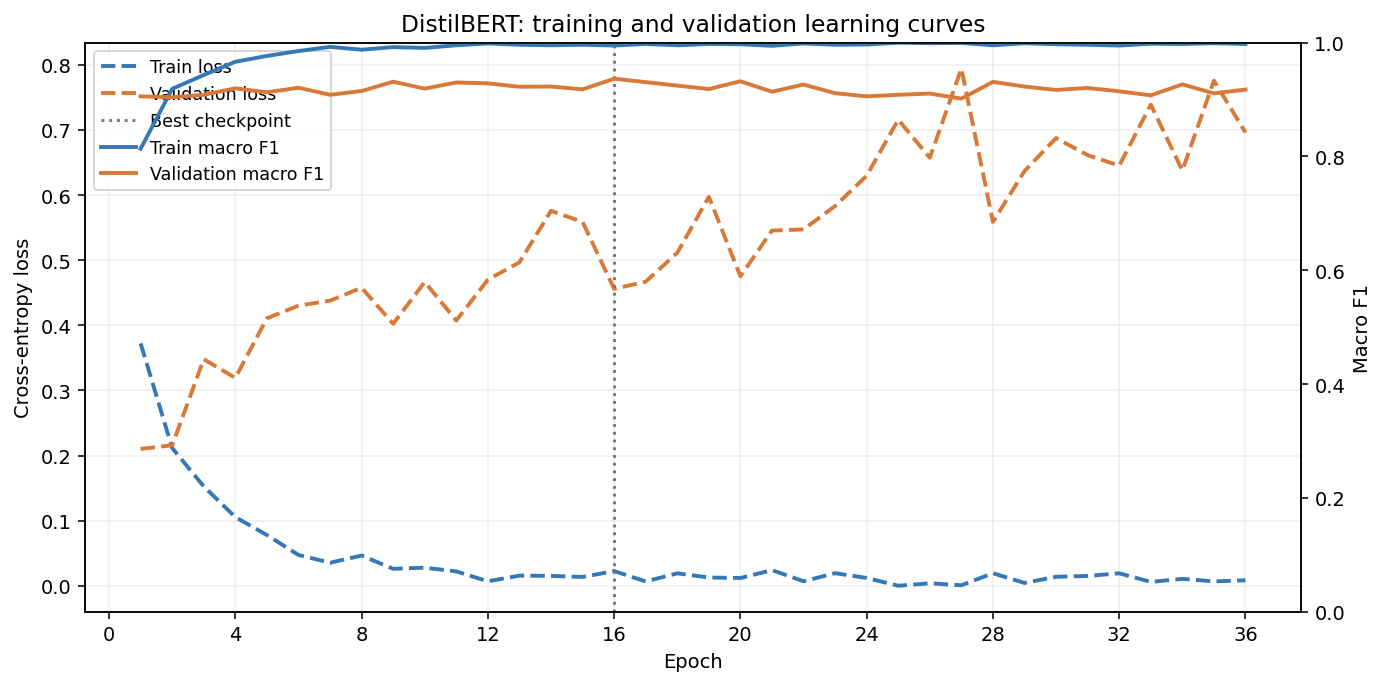

In [17]:
# Load Epoch History
history_frame = pd.read_csv(work_dir / 'training_history.csv')
best_epoch = int(history_frame.loc[history_frame['val_macro_f1'].idxmax(), 'epoch'])

# Plot Loss and Macro F1
fig, loss_ax = plt.subplots(figsize=(10, 5), dpi=140)
f1_ax = loss_ax.twinx()
train_color = '#3678b5'
val_color = '#d97938'
for split, label, color in [('train', 'Train', train_color), ('val', 'Validation', val_color)]:
    loss_ax.plot(history_frame['epoch'], history_frame[split + '_loss'],
                 color=color, linestyle='--', linewidth=2, label=f'{label} loss')
    f1_ax.plot(history_frame['epoch'], history_frame[split + '_macro_f1'],
               color=color, linestyle='-', linewidth=2, label=f'{label} macro F1')

loss_ax.axvline(best_epoch, linestyle=':', color='#777777', label='Best checkpoint')
loss_ax.set(xlabel='Epoch', ylabel='Cross-entropy loss',
            title='DistilBERT: training and validation learning curves')
f1_ax.set(ylabel='Macro F1', ylim=(0, 1))
loss_ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
loss_ax.grid(alpha=0.2)
loss_lines, loss_labels = loss_ax.get_legend_handles_labels()
f1_lines, f1_labels = f1_ax.get_legend_handles_labels()
loss_ax.legend(loss_lines + f1_lines, loss_labels + f1_labels, loc='best', fontsize=9)
fig.tight_layout()
fig.savefig(work_dir / 'training_curves.png', dpi=300, bbox_inches='tight')
plt.show()